In [ ]:
# Imports
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import re
import pandas as pd
from io import StringIO
import numpy as np
import plotly.graph_objects as go                                                                                                                                                     

In [262]:
# Simulations settings
MILP_SOLVERS = {"gurobi", "highs", "cbc", "glpk"}
RUNTIME_PREDICTION = {"safety_factor": 0.002, "alpha": 2.59, "beta": 2.41}

RAM_LIMIT = 10000  # ajustá a tu límite real en MB
TIMEOUT_LIMIT = 1800 #seg

In [244]:
# Plots settings
SOLVER = "milp"
SOLVER_COLORS = {
    SOLVER:            "#2ca02c",  
    "gurobi":          "#9467bd",  
    "highs":           "#e377c2",  
    "cbc":             "#fcdf00",  
    "glpk":            "#d62728",  
}

BLUE_PALETTE = [
    "#d0e4f7",  # very light
    "#a8cce8",  # light
    "#7ab4d9",  # medium-light
    "#4682b4",  # steelblue
    "#2e5f8a",  # medium-dark
    "#1a3d61",  # dark
]

SOLVER_LABELS = {
    "gurobi":          "Gurobi",
    "highs":           "HiGHS",
    "cbc":             "CBC",
    "glpk":            "GLPK",
}

SIZE_ORDER = ["small", "medium", "big"]
SIZE_LABELS = {
    "small":  "Pequeño\n(c ≤ 25)",
    "medium": "Mediano\n(25 < c ≤ 50)",
    "big":    "Grande\n(50 < c ≤ 80)",
}

SOLVER_BAR_COLORS = {
    SOLVER:            ["#2ca02c", "#98df8a", "#4db84e"],  
    "gurobi":          ["#9467bd", "#c5b0d5"],  
    "highs":           ["#e377c2", "#f7b6d2"],  
    "cbc":             ["#fcdf00", "#fef4a0"],  
    "glpk":            ["#d62728", "#f5a09b"],  
  }

In [245]:
# import matplotlib.pyplot as plt
# import os

# os.makedirs("figures", exist_ok=True)
# _fig_counter = [0]
# _original_show = plt.show

# def _auto_save_show():
#     _fig_counter[0] += 1
#     plt.savefig(f"/Users/tomasmarmay/Documents/famaf/tesis/src/essay/fig_{_fig_counter[0]:02d}.png", bbox_inches="tight", dpi=150)
#     _original_show()

# plt.show = _auto_save_show

In [ ]:
# Load and process data

with open("../../run_results.sql", "r") as f:
    sql = f.read()

# Extraer el bloque COPY de run_results
match = re.search(
    r"COPY public\.run_results \((.+?)\) FROM stdin;\n(.*?)\\\.",
    sql,
    re.DOTALL,
)

columns = [c.strip() for c in match.group(1).split(",")]
data = match.group(2)

df = pd.read_csv(StringIO(data), sep="\t", names=columns, na_values=["\\N"])

def filter_by_experiment_prefix(df: pd.DataFrame, prefix: str, column: str = "experiment_id") -> pd.DataFrame:
    return df[df[column].str.startswith(prefix)].copy()

def prepare_dataframe(df: pd.DataFrame):
    df = df.copy()

    def extract_size(c):
        if 0 < c <= 25:
            return "small"
        elif 25 < c <= 50:
            return "medium"
        elif 50 < c <= 80:
            return "big"
        else:
            return "large"

    df["size"] = df["c"].apply(extract_size)

    c, v, n = df["c"], df["v"], (df["c"] + 2*df["v"])     
    df['dim'] = c + (2*v)
    
    df["feasible"] = df["feasible"].map({"t": True, "f": False, True: True, False: False})
    df["valid"] = df["valid"].map({"t": True, "f": False, True: True, False: False})

    return df

df = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="turing4_MILP"))

In [272]:
# Solo solvers milps
milp = df[df["solver"].isin(MILP_SOLVERS)].copy()

# Relleno de campos ram_usage, cpu_usage
for solver in milp["solver"].unique():                                                                                                                                                
    if solver == "gurobi":                                                                                                                                                            
        continue                                                                                                                                                                      

    max_ram = milp.loc[milp["solver"] == solver, "ram_usage"].max()                                                                                                                   
    max_cpu = milp.loc[milp["solver"] == solver, "cpu_usage"].max()
                                                                                                                                                                                    
    mask = (milp["solver"] == solver) & (milp["status"] == "timeout")                                                                                                                 
    milp.loc[mask, "ram_usage"] = milp.loc[mask, "ram_usage"].fillna(max_ram)
    milp.loc[mask, "cpu_usage"] = milp.loc[mask, "cpu_usage"].fillna(max_cpu)

In [248]:
# Clasificaion por estados
status_counts = (                                                                       
    milp.groupby(["solver", "status"])                                                                                                                                                
    .size()                                                                                                                                                                           
    .unstack(fill_value=0)                                                                                                                                                            
)                                                                                                                                                                                     
status_counts_pct = status_counts.div(status_counts.sum(axis=1), axis=0) * 100

# Clasificaion por factibilidad y validez
milp_finished = milp[milp["status"] == "finished"]                                                                                                                                    
milp_feasible = milp_finished[milp_finished["feasible"] == True]                                                                                                                      
                                                                                                                                                                                    
feasible_counts = milp_finished["feasible"].map({True: "Factible", False: "Infactible"}).value_counts()                                                                               
valid_counts    = milp_feasible["valid"].map({True: "Válido", False: "Inválido"}).value_counts()                                                                                      



In [249]:
# Filtro de instancias en comun con status=finished
cv_per_solver = (
    milp[milp["status"] == "finished"]                                                                                                                                                
    .groupby("solver")                                                                                                                                                                
    .apply(lambda df: set(zip(df["c"], df["v"])))                                                                                                                                     
)                                                                                                                                                                                     
                
# Solver con menos combinaciones finished
min_solver = cv_per_solver.apply(len).idxmin()
common_cv = cv_per_solver[min_solver]                                                                                                                                                 
                                                                                                                                                                                    
# Filtrar todos los solvers a esas (c, v)                                                                                                                                             
common_cv_df = pd.DataFrame(list(common_cv), columns=["c", "v"])
milp_common = milp.merge(common_cv_df, on=["c", "v"])
milp_feasible_common = milp_common[milp_common["feasible"] == True].copy()

/tmp/ipykernel_5141/626638666.py:5: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



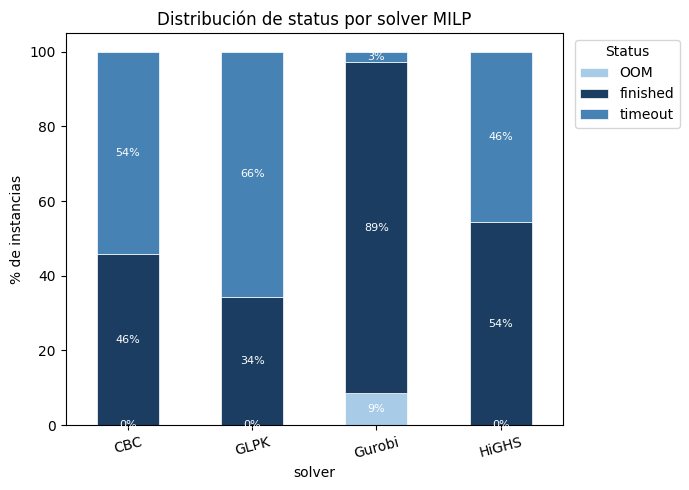

In [250]:
fig, ax = plt.subplots(figsize=(7, 5))                                                                                                                                                
status_counts_pct.plot(
    kind="bar", stacked=True, ax=ax,                                                                                                                                                  
    color=[BLUE_PALETTE[1], BLUE_PALETTE[5], BLUE_PALETTE[3]],
    edgecolor="white", linewidth=0.5,                                                                                                                                                 
)
ax.set_xticklabels([SOLVER_LABELS.get(s, s) for s in status_counts_pct.index], rotation=15)                                                                                           
ax.set_ylabel("% de instancias")                                                                                                                                                      
ax.set_ylim(0, 105)
ax.set_title("Distribución de status por solver MILP")                                                                                                                                
ax.legend(title="Status", bbox_to_anchor=(1.01, 1), loc="upper left")                                                                                                                 
for bar_group in ax.containers:
    ax.bar_label(bar_group, fmt="%.0f%%", label_type="center", fontsize=8, color="white")                                                                                             
plt.tight_layout()
plt.show()

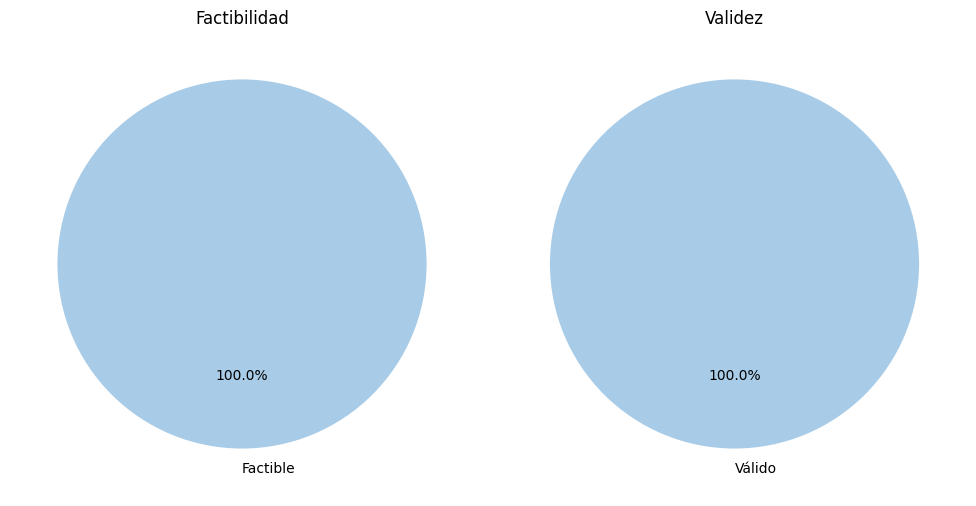

In [251]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
                                                                                                                                                                                    
for ax, counts, title in [                                                                                                                                                            
    (axes[0], feasible_counts, "Factibilidad"),
    (axes[1], valid_counts,    "Validez"),                                                                                                                     
]:              
    ax.pie(                                                                                                                                                                           
        counts.values,                                                                                                                                                                
        labels=counts.index,
        colors=[BLUE_PALETTE[1], BLUE_PALETTE[4]],                                                                                                                                   
        autopct="%1.1f%%",
        startangle=90,                                                                                                                                                                
        wedgeprops=dict(edgecolor="white", linewidth=1.5),
    )                                                                                                                                                                                 
    ax.set_title(title)
                                                                                                                                                                                    
plt.tight_layout()
plt.show()

In [ ]:
# ── Valores ────────────────────────────────────────────────────────────────────                                                                                                     
def n(mask): return milp[mask].shape[0]
                                                                                                                                                                                    
total               = milp.shape[0]
n_finished          = n(milp["status"] == "finished")                                                                                                                                 
n_timeout           = n(milp["status"] == "timeout")                                                                                                                                  
n_oom               = n(milp["status"] == "OOM")
finished_feasible   = n((milp["status"] == "finished") & (milp["feasible"] == True))                                                                                                  
finished_infeasible = n((milp["status"] == "finished") & (milp["feasible"] == False))                                                                                                 
feasible_valid      = n((milp["feasible"] == True) & (milp["valid"] == True))
feasible_invalid    = n((milp["feasible"] == True) & (milp["valid"] == False))                                                                                                        
                
# ── Nodos: 0=Total, 1=Finished, 2=Timeout, 3=OOM,                                                                                                                                    
#           4=Factible, 5=Infactible, 6=Válido, 7=Inválido
labels = ["Total", "Finished", "Timeout", "OOM", "Factible", "Infactible", "Válido", "Inválido"]                                                                                      
source = [0, 0, 0, 1, 1, 2, 3, 4, 4]
target = [1, 2, 3, 4, 5, 5, 5, 6, 7]                                                                                                                                                  
value  = [n_finished, n_timeout, n_oom,
        finished_feasible, finished_infeasible,                                                                                                                                     
        n_timeout, n_oom,
        feasible_valid, feasible_invalid]                                                                                                                                           
pcts = [                                                                                                                                                                              
    100,
    n_finished / total * 100,                                                                                                                                                         
    n_timeout  / total * 100,                                                                                                                                                         
    n_oom      / total * 100,
    finished_feasible / total * 100,                                                                                                                                                  
    (finished_infeasible + n_timeout + n_oom) / total * 100,
    feasible_valid   / total * 100,                                                                                                                                                   
    feasible_invalid / total * 100,
]

x = [0.01, 0.33, 0.33, 0.33, 0.66, 0.66, 0.99, 0.99]                                                                                                                                  
y = [0.40, 0.10, 0.50, 0.80, 0.15, 0.70, 0.10, 0.55]
x = [.001 if v==0 else .999 if v==1 else v for v in x]                                                                                                                                
y = [.001 if v==0 else .999 if v==1 else v for v in y]
                                                                                                                                                                                    
node_colors = [BLUE_PALETTE[3],
                BLUE_PALETTE[5], BLUE_PALETTE[2], BLUE_PALETTE[0],                                                                                                                     
                "#2ecc71", "#e74c3c",                                                                                                                                                  
                "#27ae60", "#c0392b"]
                                                                                                                                                                                    
link_colors = [ 
    "rgba(70,130,180,0.3)",
    "rgba(70,130,180,0.3)",                                                                                                                                                           
    "rgba(70,130,180,0.3)",
    "rgba(46,204,113,0.3)",                                                                                                                                                           
    "rgba(231,76,60,0.3)",
    "rgba(231,76,60,0.3)",                                                                                                                                                            
    "rgba(231,76,60,0.3)",
    "rgba(39,174,96,0.3)",                                                                                                                                                            
    "rgba(192,57,43,0.3)",
]                                                                                                                                                                                     

# ── Figura ─────────────────────────────────────────────────────────────────────                                                                                                     
fig = go.Figure(go.Sankey(
    textfont=dict(color="black", size=12),
    node=dict(
        pad=35, thickness=20,                                                                                                                                                         
        line=dict(color="white", width=1),
        label=[f"{name}<br>{pct:.1f}%" for name, pct in zip(["Total", "Finished", "Timeout", "OOM", "Factible", "Infactible", "Válido", "Inválido"],pcts)],
        x=x, y=y,                                                                                                                                                       
    ),                                                                                                                                                                                
    link=dict(source=source, target=target, value=value, color=link_colors),
))                                                                                                                                                                                    
                
fig.update_layout(                                                                                                                                                                    
    title="<span style='font-size:22px;color:steelblue;'><b>Flujo de ejecuciones MILP</b></span>",
    font=dict(size=12, color="white"),                                                                                                                                                
    paper_bgcolor="#F8F8FF",
)                                                                                                                                                                                     
fig.update_traces(node_color=node_colors)
fig.show()

Para poder tener una metrica comparable entre solvers, filtramos por las intancias en las que todos resolvieron. 

In [253]:
print(f"Solver limitante: {min_solver} ({len(common_cv)} combinaciones)")                                                                                                             
print(cv_per_solver.apply(len).sort_values())

Solver limitante: glpk (12 combinaciones)
solver
glpk      12
cbc       16
highs     19
gurobi    31
dtype: int64


In [254]:
t1 = (
    milp.groupby("solver")
    .apply(lambda d: pd.Series({
        "Finished": (d["status"] == "finished").sum(),
        "Total":    len(d),
    }))                                                                                                                                                                               
    .sort_values("Finished")
)                                                                                                                                                                                     
t1.index = [SOLVER_LABELS.get(s, s) for s in t1.index]
                                                                                                                                                                                    
print(t1) 

        Finished  Total
GLPK          12     35
CBC           16     35
HiGHS         19     35
Gurobi        31     35


/tmp/ipykernel_5141/1319135921.py:3: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



In [255]:
t2 = (          
    milp_feasible_common.groupby("solver")["cost"]                                                                                                                                    
    .agg(       
        Mean="mean",                                                                                                                                                                  
        Std="std",
        Median="median",                                                                                                                                                              
    )           
    .round(2)
    .sort_values("Mean")
)                                                                                                                                                                                     
t2.index = [SOLVER_LABELS.get(s, s) for s in t2.index]
                                                                                                                                                                                    
print(t2)

         Mean    Std  Median
HiGHS   45.75  18.20    42.0
CBC     46.08  18.22    42.0
GLPK    46.08  18.22    42.0
Gurobi  46.08  18.22    42.0


/tmp/ipykernel_5141/3785420719.py:9: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_5141/3785420719.py:14: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_5141/3785420719.py:21: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/tmp/ipykernel_5141/3785420719.py:9: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_5141/3785420719.py:14: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variab

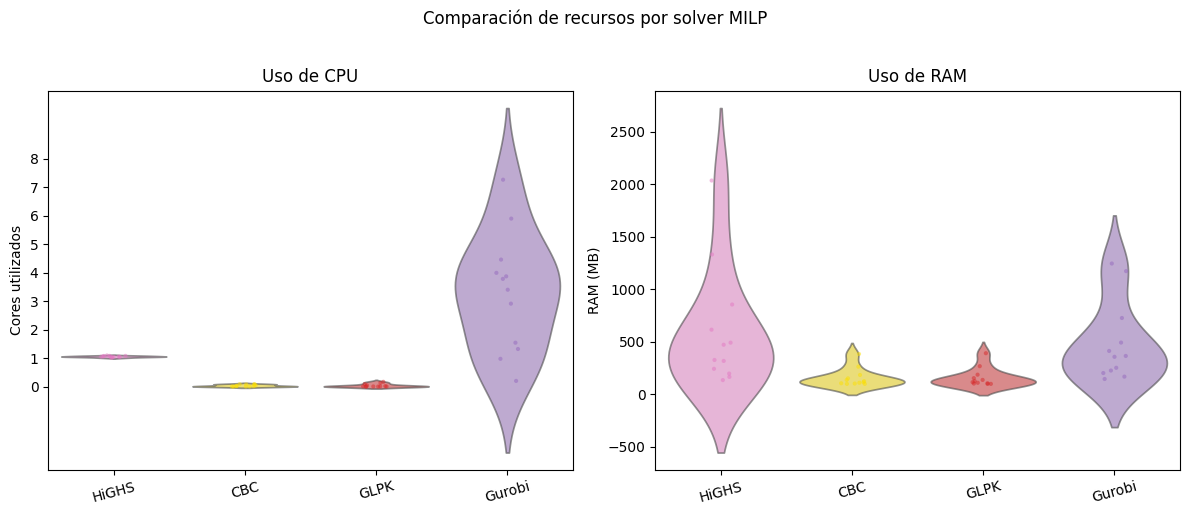

In [256]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))                                                                                                                                       
                                                                                                                                                                                    
metrics = [                                                                                                                                                                           
    ("cpu_usage", "CPU time (s)", axes[0]),                                                                                                                                            
    ("ram_usage", "RAM (MB)",    axes[1]),                                                                                                                                            
]
                                                                                                                                                                                    
for col, ylabel, ax in metrics:                                                                                                                                                       
    sns.violinplot(
        data=milp_common, x="solver", y=col, ax=ax,                                                                                                                                   
        palette={s: SOLVER_COLORS[s] for s in milp_common["solver"].unique()},                                                                                                        
        inner=None, alpha=0.6,                                                                                                                                                        
    )                                                                                                                                                                                 
    sns.stripplot(                                                                                                                                                                    
        data=milp_common, x="solver", y=col, ax=ax,                                                                                                                                   
        palette={s: SOLVER_COLORS[s] for s in milp_common["solver"].unique()},
        size=3, alpha=0.5, jitter=True,                                                                                                                                               
    )                                                                                                                                                                                 
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)                                                                                                                                                             
    ax.set_xticklabels([SOLVER_LABELS.get(s, s) for s in milp_common["solver"].unique()], rotation=15)
                                                                                                                                                                                    
axes[0].set_title("Uso de CPU")
axes[1].set_title("Uso de RAM")                                                                                                                                                       

max_cores = int(milp_common["cpu_usage"].max() / 100) + 1                                                                                                                             
axes[0].set_yticks([i * 100 for i in range(max_cores + 1)])                                                                                                                           
axes[0].set_yticklabels(range(max_cores + 1))                                                                                                                                         
axes[0].set_ylabel("Cores utilizados")                                                                                                                                                                 
plt.suptitle("Comparación de recursos por solver MILP", y=1.02)
plt.tight_layout()                                                                                                                                                                    
plt.show() 

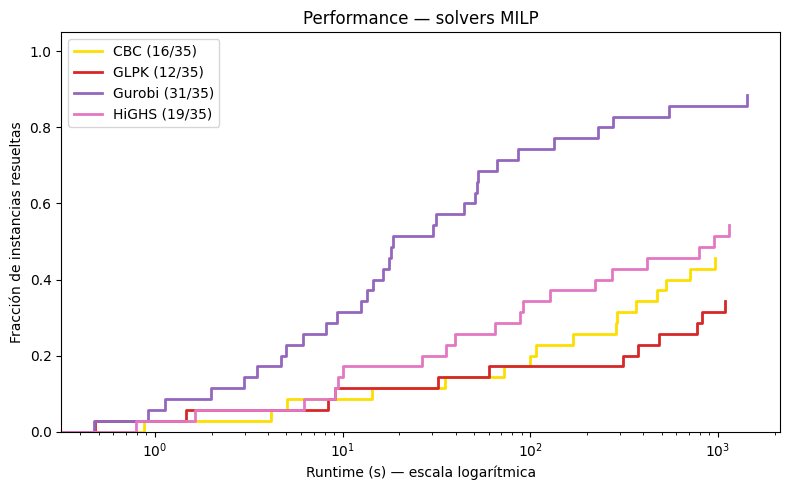

In [257]:
fig, ax = plt.subplots(figsize=(8, 5))                                                                                                                                                
                                                                                                                                                                                    
for solver, data in milp.groupby("solver"):                                                                                                                                    
    total = data[["c", "v"]].drop_duplicates().shape[0]
                                                                                                                                                                                    
    finished = (                                                                                                                                                                      
        data[data["status"] == "finished"]
        .drop_duplicates(subset=["c", "v"])["runtime"]                                                                                                                                
        .sort_values()
    )

    x = [0] + list(finished) + [finished.max() if len(finished) else 0]                                                                                                               
    y = [0] + [i/total for i in range(1, len(finished)+1)] + [len(finished)/total]
                                                                                                                                                                                    
    ax.step(x, y, where="post",                                                                                                                                                       
            color=SOLVER_COLORS.get(solver),
            label=f"{SOLVER_LABELS.get(solver, solver)} ({len(finished)}/{total})",                                                                                                   
            linewidth=2)                                                                                                                                                              


ax.set_xscale("log")                                                                                                                                                                  
ax.set_xlabel("Runtime (s) — escala logarítmica")
ax.set_ylabel("Fracción de instancias resueltas")
ax.set_title("Performance — solvers MILP")                                                                                                                                    
ax.set_ylim(0, 1.05)
ax.legend()                                                                                                                                                                           
plt.tight_layout()
plt.show()

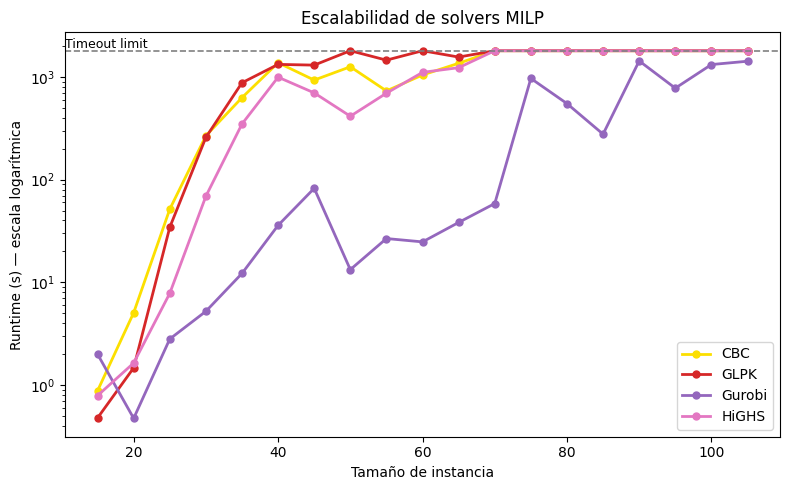

In [264]:
runtime_by_size = (                                                                                                                                                                   
    milp
    .groupby(["solver", "dim"])["runtime"]
    .mean()                                                                                                                                                                           
    .reset_index()
)
                                                                                                                                                                                    
fig, ax = plt.subplots(figsize=(8, 5))
                                                                                                                                                                                    
for solver, data in runtime_by_size.groupby("solver"):
    data = data.sort_values("dim")
    ax.plot(data["dim"], data["runtime"],                                                                                                                                   
            marker="o", label=SOLVER_LABELS.get(solver, solver),
            color=SOLVER_COLORS.get(solver), linewidth=2, markersize=5)                                                                                                               
                                                                                                                                                                                    
ax.set_yscale("log")                                                                                                                                                                  
ax.set_xlabel("Tamaño de instancia")                                                                                                                                          
ax.set_ylabel("Runtime (s) — escala logarítmica")
ax.set_title("Escalabilidad de solvers MILP")
ax.axhline(TIMEOUT_LIMIT, color="gray", linestyle="--", linewidth=1.2)                                                                                                                         
ax.text(ax.get_xlim()[0], TIMEOUT_LIMIT, "Timeout limit", va="bottom", ha="left", color="black", fontsize=9)                                                                                                                                   
ax.legend()
plt.tight_layout()                                                                                                                                                                    
plt.show()

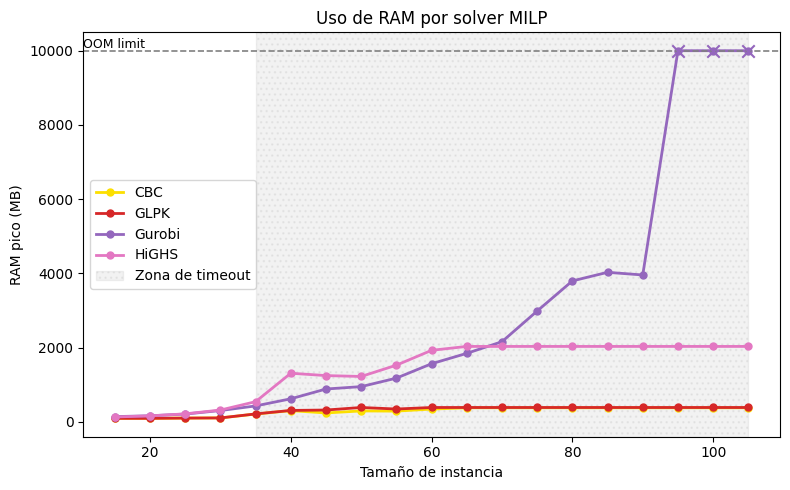

In [ ]:
ram_by_size = (                                                                                                                                                                       
    milp[milp["ram_usage"] != None]
    .groupby(["solver", "dim"])["ram_usage"]                                                                                                                                
    .mean()     
    .reset_index()                                                                                                                                                                    
)

fig, ax = plt.subplots(figsize=(8, 5))                                                                                                                                                
                
for solver, data in ram_by_size.groupby("solver"):
    data = data.sort_values("dim")
    ax.plot(data["dim"], data["ram_usage"],                                                                                                                                 
            marker="o", label=SOLVER_LABELS.get(solver, solver),
            color=SOLVER_COLORS.get(solver), linewidth=2, markersize=5)                                                                                                               
                                                                                                                                                                                    
# OOM como puntos en el límite                                                                                                                                                        
for solver, data in milp[milp["status"] == "OOM"].groupby("solver"):                                                                                                          
    ax.scatter(data["dim"], [RAM_LIMIT] * len(data),                                                                                                                        
                marker="x", s=80, color=SOLVER_COLORS.get(solver), zorder=5)                                                                                                           
                                                                                                                                                                                    
ax.axhline(RAM_LIMIT, color="gray", linestyle="--", linewidth=1.2)                                                                                                                    
ax.text(ax.get_xlim()[0], RAM_LIMIT, "OOM limit", va="bottom", ha="left", color="black", fontsize=9)                                                                                  
                                                                                                                                                                                    
ax.set_xlabel("Tamaño de instancia")                                                                                                                                          
ax.set_ylabel("RAM pico (MB)")
ax.set_title("Uso de RAM por solver MILP")       

timeout_min = milp[(milp["status"] == "timeout") & (milp["solver"] != "gurobi")]["dim"].min()                                                                                         
timeout_max = milp[(milp["status"] == "timeout") & (milp["solver"] != "gurobi")]["dim"].max()
                                                                                                                                                                                    
ax.axvspan(timeout_min, timeout_max, color="gray", alpha=0.1, hatch="...", label="Zona de timeout")                                                                                               

ax.legend()                                                                                                                                                                           
plt.tight_layout()
plt.show()